# 14 — Los estados del triage frente a todo el entorno

## Pregunta y alcance

Un hospital no necesita saber solo cuánta gente llegará, sino **qué clase de día** viene: uno que
se sale por arriba de lo que su calendario anunciaba (pico), uno que se queda por debajo (bajo), uno
sin sorpresas (normal) y un tramo en que la serie está tranquila o agitada (estabilidad). Este
cuaderno define esos estados sobre el conteo diario de triage y los enfrenta a todo el entorno
disponible: clima, vigilancia en salud, seguridad, eventos, fiestas, días especiales y ENSO. La
granularidad es año-mes-día, sin hora.

Los cuadernos 12 y 13 enfrentaron el entorno al triage por semanas, y el 07, el 08 y el 11
mecanismo por mecanismo. Aquí el barrido se hace por días y, en una segunda parte, se rehace con
la lógica de los mecanismos: cada factor tiene un reloj (cuánto tarda en actuar), un gatillo (el
cambio o el evento que lo enciende, no su nivel), una condición (cuándo puede actuar) y un
subgrupo (quién consulta por él). Un barrido que trata los 2.000 días por igual y mide solo el
efecto medio diluye todo lo que ocurre en unos pocos episodios. La primera versión de este
análisis concluyó que ninguna fuente externa anticipa los estados de forma estable; las secciones 6
a 9 comprueban si esa conclusión resiste cuando el diseño sí puede ver lo episódico.

## Método

El método de los estados se fijó antes de revisar los resultados. Las pruebas de las secciones 6 a
9 (marcas de tipo de día, calma, asegurador y transición) se añadieron después de la primera
corrida y se declaran como exploratorias.

- **El estado no se define sobre el conteo crudo.** Sobre el crudo, los picos son lunes y los bajos
  domingos, y eso es proyección. Se quita primero lo que ya explican:
  - el **calendario**: día de la semana, festivo, puente, víspera, día posterior al festivo,
    quincena, vacaciones escolares, Semana Santa, Navidad, fin de año y regreso a clases;
  - el **nivel de la red**: el año y los escalones de Nueva EPS (2024-04, 2025-11, 2026-03 y 2026-07).
- **La estación se conserva**, porque el clima y la vigilancia podrían explicarla.
- **Estados**, sobre z = residuo / desviación típica: pico, z > +1; bajo, z < −1; normal,
  |z| ≤ 0,5; intermedio, el resto.
- **Estabilidad:** desviación típica móvil del residuo en 14 días. El tercil bajo es estable y el
  alto, agitado.
- **Prueba:** exposición estandarizada ~ 1[pico] + 1[bajo], con errores HAC de 7 días, con y sin
  mes fijo. Benjamini-Hochberg con q = 0,10 dentro de cada familia. Se descubre en 2022-03 a
  2024-12 y se confirma en 2025-01 a 2026-09. **Solo cuenta lo que se confirma con el mismo signo y
  con el mes fijo.**
- **Lo del mismo día es descriptivo.** Para predecir solo sirve lo que ocurre antes.

## De dónde salen los datos

| Familia | Archivo | Qué se usa |
|---|---|---|
| Triage | `salidas/triage_diario.parquet`, `triage_edad.parquet`, `triage_entidad.parquet` | conteo diario, bandas de edad, asegurador |
| Calendario (control) | `calendarios/calendario_Colombia.csv` | festivos, puentes, vacaciones, temporadas |
| Clima | `calendarios/clima_unificado.csv.gz` | temperatura, amplitud, humedad, lluvia (día, 7 y 30 días), radiación, viento |
| Vigilancia | `vigilancia_sivigila.csv.gz`, `vigilancia_sivigila_eventos.csv.gz` | IRA, IRAG, EDA y 5 eventos de Manizales, por semana (hasta 2025-12) |
| Seguridad | `seguridad_mindefensa.csv.gz` | lesiones de tránsito, lesiones personales, homicidio, violencia intrafamiliar |
| Eventos | `eventos_manizales_2020_2026.csv`, `fiestas_caldas_2020_2026.csv`, `desastres_manizales_2020_2026.csv` | Feria y eventos por categoría, fiestas por distancia, desastres |
| Días especiales | `calendario_Colombia.csv` | día de la madre, amor y amistad, velitas, Halloween (no están en el control) |
| ENSO | `enso_oni.csv` | ONI del mes y de 3 meses antes |
| Tipos de día | `notebooks/marcas.py` | ocho marcas construidas solo con el calendario y las variables externas, sin mirar el triage |

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from matplotlib import pyplot as plt

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
GRIS_CLARO = "#d9d8d4"
COLOR_ESTADO = {"pico": ROJO, "intermedio": GRIS_CLARO, "normal": MUDO, "bajo": AZUL}
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
pct = lambda x: (np.exp(x) - 1) * 100
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
SEM = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]

INI, FIN = "2022-03-01", "2026-09-20"
DESC, CONF = ("2022-03-01", "2024-12-31"), ("2025-01-01", "2026-09-20")
ESCALONES_RED = ["2024-04-01", "2025-11-15", "2026-03-01", "2026-07-01"]       # desenlace.py
CAL = ["es_festivo", "es_puente", "es_vispera_festivo", "es_post_festivo", "es_quincena",
       "es_vacaciones_escolares", "es_semana_santa", "es_temporada_navidad", "es_temporada_fin_anio",
       "es_regreso_colegio"]
dias = pd.date_range(INI, FIN)
tri = (pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
         .set_index("dia")["triages"].reindex(dias).astype(float))
tri["2024-03-19":"2024-03-21"] = np.nan                       # caida de registro, no cero pacientes
cal = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
calc = cal[CAL].apply(pd.to_numeric, errors="coerce").fillna(0)
dsem = pd.get_dummies(pd.Index(dias.dayofweek), prefix="d", drop_first=True).set_index(dias).astype(float)
anio = pd.get_dummies(pd.Index(dias.year), prefix="a", drop_first=True).set_index(dias).astype(float)
red = pd.DataFrame({f"red{i}": (dias >= f).astype(float) for i, f in enumerate(ESCALONES_RED)}, index=dias)

def ajusta(Z, y=tri):
    Z = Z.copy(); Z.insert(0, "c", 1.0)
    ly = np.log(y); ok = ly.notna()
    b, *_ = np.linalg.lstsq(Z[ok].values, ly[ok].values, rcond=None)
    return (ly - Z.values @ b).where(ok)

def estados(r):
    z = r / r.std()
    e = pd.Series("intermedio", index=r.index)
    e[z > 1] = "pico"; e[z < -1] = "bajo"; e[z.abs() <= .5] = "normal"; e[z.isna()] = np.nan
    return e

R_nivel = ajusta(pd.concat([anio, red], axis=1))              # solo el nivel: lo que ve el ojo sobre el crudo
R_sem = ajusta(pd.concat([dsem, anio, red], axis=1))          # + dia de la semana
R = ajusta(pd.concat([dsem, calc, anio, red], axis=1))        # control completo
estado, estado_crudo = estados(R), estados(R_nivel)
vol = R.rolling(14, center=True, min_periods=10).std()
print(f"{tri.notna().sum()} días, {dias[0].date()} a {dias[-1].date()}")
print(f"desviación típica del residuo: solo nivel {R_nivel.std():.3f} · + día de semana {R_sem.std():.3f} · + calendario {R.std():.3f}")

1662 días, 2022-03-01 a 2026-09-20
desviación típica del residuo: solo nivel 0.199 · + día de semana 0.131 · + calendario 0.106


---
# 1. Qué queda del pico cuando se quita el calendario

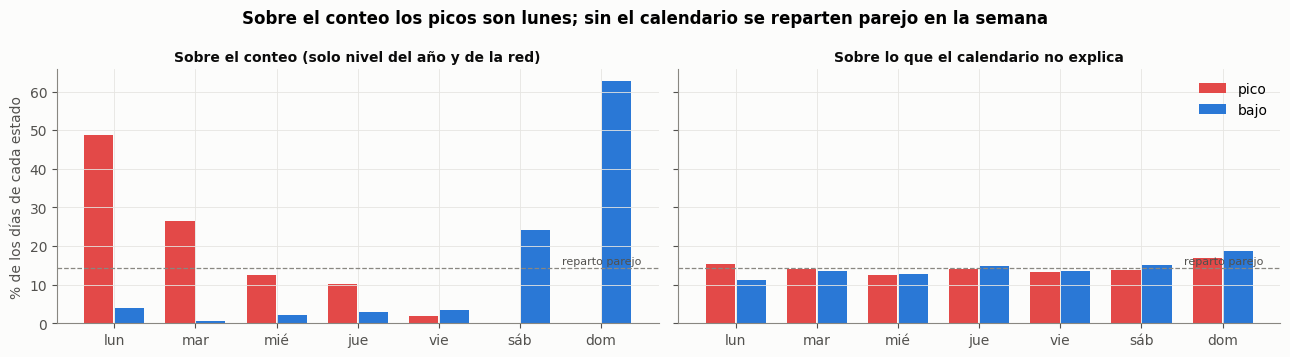

El día de la semana explica el 56.5% de la variación diaria (sin el nivel); con el resto del calendario, el 72.0%.
De 264 picos del conteo, siguen siendo pico 116 (44%). De 297 bajos, siguen 111.
Picos del conteo en lunes: 49%; bajos del conteo en fin de semana: 87%


estado sin calendario,bajo,intermedio,normal,pico
estado sobre el conteo,,,,
bajo,111,79,99,8
intermedio,65,153,218,73
normal,74,176,291,51
pico,0,66,82,116


In [2]:
v_sem = 1 - R_sem.var() / R_nivel.var(); v_cal = 1 - R.var() / R_nivel.var()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, e, t in [(axes[0], estado_crudo, "Sobre el conteo (solo nivel del año y de la red)"),
                 (axes[1], estado, "Sobre lo que el calendario no explica")]:
    tab = pd.crosstab(dias.dayofweek, e, normalize="columns") * 100
    for j, (k, col) in enumerate([("pico", ROJO), ("bajo", AZUL)]):
        ax.bar(np.arange(7) + (j - .5) * .38, tab[k].values, width=.36, color=col, label=k)
    ax.axhline(100 / 7, color=MUDO, lw=.9, ls="--"); ax.text(6.5, 100 / 7 + 1, "reparto parejo", ha="right", fontsize=8, color=TINTA2)
    ax.set_xticks(range(7), SEM); ax.set_title(t, fontsize=10)
axes[0].set_ylabel("% de los días de cada estado"); axes[1].legend(loc="upper right")
fig.suptitle("Sobre el conteo los picos son lunes; sin el calendario se reparten parejo en la semana", fontweight="bold"); plt.tight_layout(); plt.show()

cruce = pd.crosstab(estado_crudo.rename("estado sobre el conteo"), estado.rename("estado sin calendario"))
print(f"El día de la semana explica el {v_sem:.1%} de la variación diaria (sin el nivel); con el resto del calendario, el {v_cal:.1%}.")
print(f"De {cruce.loc['pico'].sum()} picos del conteo, siguen siendo pico {cruce.loc['pico','pico']} "
      f"({cruce.loc['pico','pico'] / cruce.loc['pico'].sum():.0%}). De {cruce.loc['bajo'].sum()} bajos, siguen {cruce.loc['bajo','bajo']}.")
print(f"Picos del conteo en lunes: {(dias.dayofweek[(estado_crudo == 'pico').values] == 0).mean():.0%}; bajos del conteo en fin de semana: {(dias.dayofweek[(estado_crudo == 'bajo').values] >= 5).mean():.0%}")
cruce

**Lectura.** Sobre el conteo, casi la mitad de los picos caen en lunes (49 %) y el 87 % de los bajos en
fin de semana: es lo que se proyecta sin pensar. **El calendario explica el 72 % de la variación
diaria**, y el día de la semana solo, el 57 %. Solo el 44 % de los picos del conteo siguen siendo
pico cuando se quita el calendario, y lo que queda se reparte parejo entre los siete días, de modo
que el control cumple su función. Desde aquí, «pico» significa **un día más alto de lo que su
calendario anunciaba**, que es lo que interesa predecir. La cautela es que el control mismo se
estima con los datos de la ventana, de modo que parte de la variación que absorbe podría ser
estacional.

---
# 2. Cuánto pesan, cuánto duran y cuándo caen los estados

,días,% de días,desvío medio %,racha media (días),racha máx.,P(mismo estado mañana) %
pico,248,14.9,17.3,1.40,7,28.6
intermedio,474,28.5,0.4,1.39,5,28.3
normal,690,41.5,0.1,1.76,9,43.3
bajo,250,15.0,-15.5,1.31,6,23.6


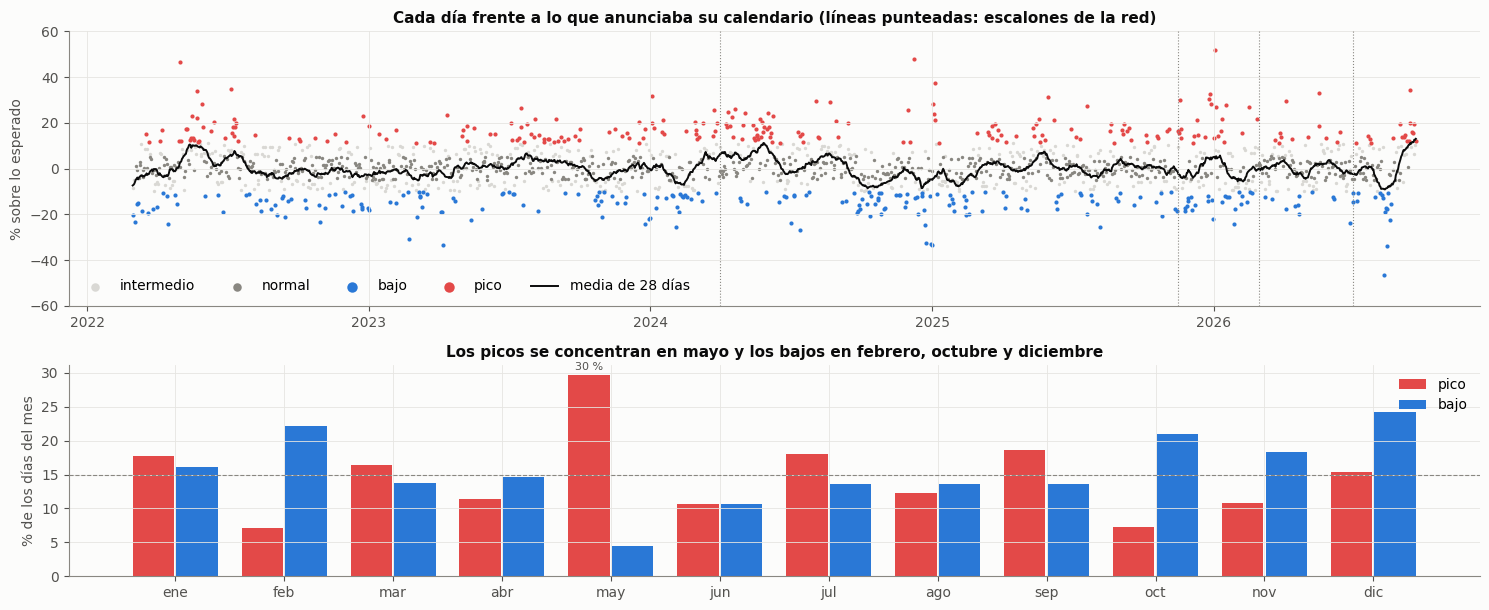

Autocorrelación del residuo a 1 día: +0.26; ruido de fondo (desviación típica del residuo): 11.1 %; base de pico: 14.9%


row_0,1,2,3,4,5,6,7,8,9,10,11,12
col_0,,,,,,,,,,,,
pico,17.7,7.1,16.4,11.3,29.7,10.7,18.1,12.3,18.6,7.3,10.8,15.3
normal,31.5,39.8,40.1,45.3,34.8,48.0,41.3,43.9,41.4,43.5,48.3,39.5
bajo,16.1,22.1,13.8,14.7,4.5,10.7,13.5,13.5,13.6,21.0,18.3,24.2


In [3]:
res = pd.DataFrame({"días": estado.value_counts(), "% de días": (estado.value_counts(normalize=True) * 100).round(1),
                    "desvío medio %": R.groupby(estado).mean().pipe(pct).round(1)}).loc[["pico", "intermedio", "normal", "bajo"]]
e = estado.fillna("na"); g = (e != e.shift()).cumsum()
rachas = e.groupby(g).agg(["first", "size"]).query("first != 'na'")
res["racha media (días)"] = rachas.groupby("first")["size"].mean().round(2)
res["racha máx."] = rachas.groupby("first")["size"].max()
res["P(mismo estado mañana) %"] = [round(100 * ((estado == k) & (estado.shift(-1) == k)).sum() / (estado == k).sum(), 1) for k in res.index]
display(res)

fig, axes = plt.subplots(2, 1, figsize=(15, 6.2), gridspec_kw={"height_ratios": [1.3, 1]})
ax = axes[0]
for k in ["intermedio", "normal", "bajo", "pico"]:
    m = (estado == k).values
    ax.scatter(dias[m], pct(R[m]), s=6 if k in ("normal", "intermedio") else 9, color=COLOR_ESTADO[k], label=k, lw=0)
ax.plot(dias, pct(R.rolling(28, center=True, min_periods=14).mean()), color=TINTA, lw=1.4, label="media de 28 días")
for f in ESCALONES_RED: ax.axvline(pd.Timestamp(f), color=MUDO, lw=.8, ls=":")
ax.set_ylabel("% sobre lo esperado"); ax.set_ylim(-60, 60); ax.legend(ncol=5, loc="lower left", markerscale=2.5)
ax.set_title("Cada día frente a lo que anunciaba su calendario (líneas punteadas: escalones de la red)")
ax = axes[1]
tab = pd.crosstab(dias.month, estado, normalize="index") * 100
x = np.arange(12)
ax.bar(x - .2, tab["pico"], width=.38, color=ROJO, label="pico"); ax.bar(x + .2, tab["bajo"], width=.38, color=AZUL, label="bajo")
ax.axhline(15, color=MUDO, lw=.8, ls="--")
i = tab["pico"].values.argmax(); ax.text(i - .2, tab["pico"].max() + .8, f"{tab['pico'].max():.0f} %", ha="center", fontsize=8, color=TINTA2)
ax.set_xticks(x, MESES); ax.set_ylabel("% de los días del mes"); ax.legend(loc="upper right")
ax.set_title("Los picos se concentran en mayo y los bajos en febrero, octubre y diciembre")
plt.tight_layout(); plt.show()
print(f"Autocorrelación del residuo a 1 día: {R.autocorr(1):+.2f}; ruido de fondo (desviación típica del residuo): {pct(R.std()):.1f} %; base de pico: {(estado == 'pico').mean():.1%}")
tab.round(1)[["pico", "normal", "bajo"]].T

**Lectura.** Un pico pesa **+17 %** sobre lo esperado y un bajo **−15,5 %**, frente a un ruido de fondo
del día de 11,1 % (0,106 en logaritmos). Los picos son de un día: la racha media es de 1,4 días y la probabilidad de que
el día posterior también sea pico es del 29 %, el doble de la base (15 %) pero lejos de una
certeza. Esa memoria corta es la del residuo (autocorrelación de +0,26 a un día). La estación pesa
mucho: **mayo concentra picos (30 % de sus días)** y casi no tiene bajos (4,5 %), mientras que
febrero y octubre tienen 7 % de picos y 21-22 % de bajos, y diciembre tiene 24 % de bajos. Es la
temporada respiratoria de mitad de año que ya se vio en los cuadernos 02 y 08, y la caída de fin
de año que producen las vacaciones. Como la estación se conservó a propósito, esta figura no
distingue entre clima y calendario escolar como causa.

---
# 3. Quién llena el pico: la demanda entera y no un grupo

Si el pico fuera epidemiológico (una ola respiratoria), debería cargarse sobre los niños. Si es de
acceso (la red, el sistema, un día raro), debería subir todo el mundo a la vez. Se ajusta el
**mismo control a cada banda de edad** y se mira su desvío en cada estado.

In [4]:
ed = pd.read_parquet(RAIZ / "salidas/triage_edad.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
E = ed.pivot_table(index="dia", columns="banda", values="n", aggfunc="sum").reindex(dias).fillna(0)
E = E[["0-4", "5-14", "15-44", "45-64", "65-+"]]; E[tri.isna()] = np.nan
Zc = pd.concat([dsem, calc, anio, red], axis=1)
Rb = pd.DataFrame({b: ajusta(Zc, E[b].clip(lower=.5)) for b in E.columns})
desv = pct(Rb.groupby(estado).mean()).loc[["pico", "normal", "bajo"]].round(1)
peso = (E.groupby(estado).mean().T / E.groupby(estado).mean().sum(axis=1)).T.loc[["pico", "normal", "bajo"]].mul(100).round(1)
pd.concat({"desvío sobre lo esperado, %": desv, "peso en el día, %": peso}, axis=1)

desvío sobre lo esperado, %                         peso en el día, %  \
                               0-4  5-14 15-44 45-64  65-+               0-4   
pico                          27.1  23.4  16.7  17.3  16.1               3.6   
normal                        -1.5  -0.4   0.5  -0.2  -0.2               3.3   
bajo                         -15.5 -17.3 -16.0 -14.5 -14.5               3.3   

                               
       5-14 15-44 45-64  65-+  
pico    5.0  53.4  18.4  19.5  
normal  4.8  53.9  18.3  19.7  
bajo    4.8  53.1  18.6  20.1

**Lectura.** En un pico sube todo el mundo, de +16 % a +27 % según la banda, y en un bajo cae todo
el mundo, de −14 % a −17 %. Los niños suben algo más (0-4 años, +27 %; 5-14, +23 %), pero la
composición del día casi no cambia: la banda de 15-44 años sigue siendo alrededor de la mitad en
pico, en normal y en bajo. Un pico no es un grupo que llega, es la demanda entera que se corre, y
eso apunta más a **acceso y sistema** que a una ola epidemiológica, que se cargaría sobre un grupo.
Encaja con que la vigilancia no mueva el total (cuaderno 13). La cautela es que una ola que sube
solo un 3 % del total en niños no se vería en estos porcentajes, que son del conteo de cada banda.

---
# 4. Estabilidad: cuándo está tranquila la serie y cuándo agitada

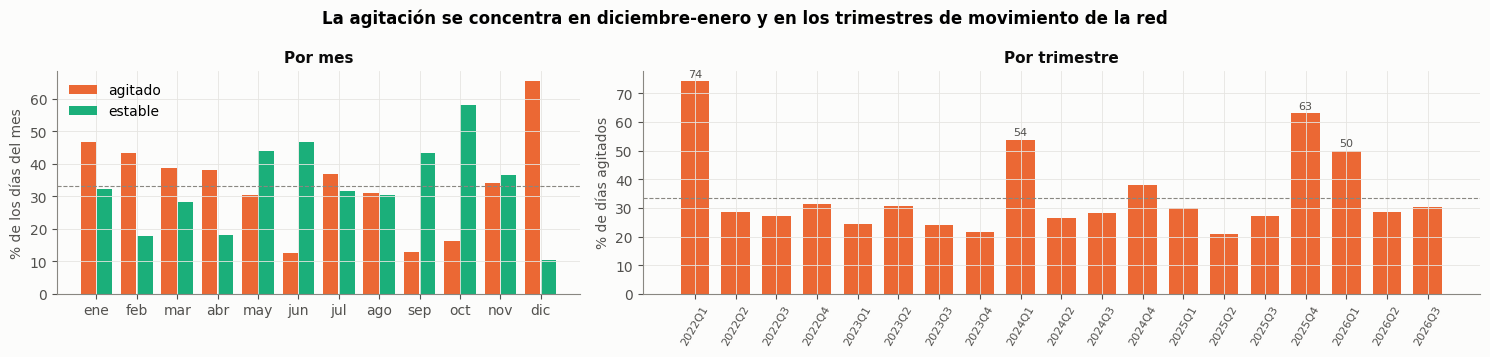

% de días agitados por mes: {1: 47, 2: 43, 3: 39, 4: 38, 5: 30, 6: 13, 7: 37, 8: 31, 9: 13, 10: 16, 11: 34, 12: 65}
Trimestres más agitados: {Period('2024Q4', 'Q-DEC'): 38, Period('2026Q1', 'Q-DEC'): 50, Period('2024Q1', 'Q-DEC'): 54, Period('2025Q4', 'Q-DEC'): 63, Period('2022Q1', 'Q-DEC'): 74}


In [5]:
q = vol.quantile([1 / 3, 2 / 3])
ag = pd.cut(vol, [-1, q.iloc[0], q.iloc[1], 9], labels=["estable", "medio", "agitado"])
fig, axes = plt.subplots(1, 2, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
tm = pd.crosstab(dias.month, ag, normalize="index") * 100
axes[0].bar(np.arange(12) - .2, tm["agitado"], width=.38, color=NARANJA, label="agitado")
axes[0].bar(np.arange(12) + .2, tm["estable"], width=.38, color=AQUA, label="estable")
axes[0].axhline(100 / 3, color=MUDO, lw=.8, ls="--"); axes[0].set_xticks(range(12), MESES)
axes[0].set_ylabel("% de los días del mes"); axes[0].legend(); axes[0].set_title("Por mes")
tq = ag.eq("agitado").groupby(dias.to_period("Q")).mean() * 100
axes[1].bar(range(len(tq)), tq.values, color=NARANJA, width=.7)
axes[1].axhline(100 / 3, color=MUDO, lw=.8, ls="--")
axes[1].set_xticks(range(len(tq)), [str(p) for p in tq.index], rotation=60, fontsize=8)
for i in np.argsort(tq.values)[-4:]: axes[1].text(i, tq.values[i] + 1.5, f"{tq.values[i]:.0f}", ha="center", fontsize=8, color=TINTA2)
axes[1].set_ylabel("% de días agitados"); axes[1].set_title("Por trimestre")
fig.suptitle("La agitación se concentra en diciembre-enero y en los trimestres de movimiento de la red", fontweight="bold")
plt.tight_layout(); plt.show()
print("% de días agitados por mes:", (tm["agitado"].round(0).astype(int)).to_dict())
print("Trimestres más agitados:", tq.sort_values().tail(5).round(0).astype(int).to_dict())

**Lectura.** La agitación (tercil alto de la desviación típica del residuo en 14 días) tiene dos
fuentes, y ninguna es el clima. La primera es la temporada festiva: diciembre tiene el 65 % de sus
días agitados y enero el 47 %, la noche festiva del cuaderno 08, que el calendario controla en
promedio pero no noche por noche. La segunda son los choques de la red: 2022-T1 (74 %, final de la COVID),
2024-T1 (54 %), **2025-T4 (63 %)**, cuando empiezan los cierres a Nueva EPS, y 2026-T1 (50 %), trimestres
en que el nivel de la red se estaba moviendo. Lo más estable son junio, septiembre y octubre (13 a
16 % de días agitados).

---
# 5. El barrido día a día: lo que encuentra el entorno medio

Primera forma de enfrentar el entorno: para cada exposición y ventana se mide cuánto se desplaza
(en desviaciones típicas) en los días pico y en los días bajo frente al resto, en el periodo de
descubrir y en el de confirmar, con y sin el mes fijo. Son 163 exposiciones y 326 pruebas. Esta
forma de mirar promedia todos los días, tengan o no encendido el gatillo del factor, y es la que
las secciones 6 a 9 ponen en cuestión.

In [6]:
todos = pd.date_range("2019-12-01", FIN)
VENT = {"t": (0, 0), "t-1a3": (1, 3), "t-4a7": (4, 7), "t-8a14": (8, 14), "t-15a28": (15, 28)}
cols, fam = {}, {}
def pon(k, s, f): cols[k] = s; fam[k] = f

# clima: anomalia contra la climatologia del mes, en ventanas; y cambio a 3 y 7 dias
c = pd.read_csv(RAIZ / "calendarios/clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha").reindex(todos)
c["amplitud"] = c.temp_max_consenso - c.temp_min_consenso
CLI = {"temp_media": "temp_media_consenso", "temp_min": "temp_min_consenso", "temp_max": "temp_max_consenso",
       "amplitud": "amplitud", "humedad": "humedad_consenso", "lluvia_dia": "precip_consenso_mm",
       "lluvia_7d": "precip_7d", "lluvia_30d": "precip_30d", "radiacion": "radiacion_consenso", "viento": "viento_consenso_ms"}
for nom, col in CLI.items():
    x = c[col].astype(float)
    if nom.startswith("lluvia"): x = np.log1p(x)
    an = x - x.groupby(x.index.month).transform("mean")
    if nom in ("lluvia_7d", "lluvia_30d"):                  # ya son acumulados: tres cortes
        for k, l in {"t-1": 1, "t-8": 8, "t-15": 15}.items(): pon(f"{nom}|{k}", an.shift(l), "clima")
    else:
        for k, (a, b) in VENT.items(): pon(f"{nom}|{k}", an.shift(a).rolling(b - a + 1, min_periods=max(1, (b - a + 1) // 2)).mean(), "clima")
    m3, m7 = x.rolling(3).mean(), x.rolling(7).mean()
    pon(f"{nom}_cambio3|t-1", (m3 - m3.shift(3)).shift(1), "clima")
    pon(f"{nom}_cambio7|t-1", (m7 - m7.shift(7)).shift(1), "clima")

# vigilancia semanal de Manizales: anomalia dentro del anio (conserva la estacion), misma semana y 1-2 antes
v = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila.csv.gz", parse_dates=["fecha_inicio_semana"]).query("ambito == 'manizales'")
ev_ = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_eventos.csv.gz", parse_dates=["fecha_inicio_semana"])
ev_ = ev_[ev_.ambito.eq("manizales") & ev_.variable.eq("casos_notificacion")]
VIG = {"ira_total": (v, 995, "consultas_ira_total"), "ira_0_4": (v, 995, "consultas_ira_0_4"),
       "ira_60_mas": (v, 995, "consultas_ira_60_mas"), "irag_hosp": (v, 995, "hospitalizaciones_irag_total"),
       "eda_total": (v, 998, "casos_eda_total"), "consultas_todas": (v, 995, "consultas_todas_causas_total"),
       "agresion_animal_300": (ev_, 300, "casos_notificacion"), "violencia_genero_875": (ev_, 875, "casos_notificacion"),
       "intoxicacion_365": (ev_, 365, "casos_notificacion"), "intento_suicidio_356": (ev_, 356, "casos_notificacion"),
       "varicela_831": (ev_, 831, "casos_notificacion")}
domingo = todos - pd.to_timedelta((todos.dayofweek + 1) % 7, unit="D")
for nom, (df, cod, var) in VIG.items():
    w = df[df.evento.eq(cod) & df.variable.eq(var)].set_index("fecha_inicio_semana")["valor"].astype(float).sort_index()
    w = w[~w.index.duplicated()]
    if cod == 998: w[w.index == pd.Timestamp("2025-12-28")] = np.nan       # SE53-2025 del 998: error de la fuente
    lw = np.log1p(w); an = lw - lw.groupby(lw.index.year).transform("mean")
    for k, l in {"misma_sem": 0, "sem-1": 1, "sem-2": 2}.items():
        pon(f"{nom}|{k}", pd.Series(an.reindex(domingo - pd.Timedelta(weeks=l)).values, index=todos), "vigilancia")

# seguridad MinDefensa, diaria, relativa a su anio
sg = pd.read_csv(RAIZ / "calendarios/seguridad_mindefensa.csv.gz", parse_dates=["fecha"]).set_index("fecha").reindex(todos)
for col in ["lesiones_transito", "lesiones_personales", "homicidio", "violencia_intrafamiliar"]:
    x = sg[col].astype(float); x = x / x.groupby(x.index.year).transform("mean")
    for k, s in {"t": x, "t-1a3": x.shift(1).rolling(3).mean(), "t-4a7": x.shift(4).rolling(4).mean()}.items(): pon(f"{col}|{k}", s, "seguridad")

# eventos de Manizales, fiestas de Caldas por distancia, desastres
def activo(df):
    s = pd.Series(0.0, index=todos)
    for _, r in df.dropna(subset=["fecha_inicio"]).iterrows():
        a = pd.Timestamp(r.fecha_inicio); b = pd.Timestamp(r.fecha_fin) if pd.notna(r.fecha_fin) else a
        s[a:b] += 1
    return s
evm = pd.read_csv(RAIZ / "calendarios/eventos_manizales_2020_2026.csv").query("estado in ['realizado', 'programado']")
for cat, g in {"feria": ["feria", "taurino"], "religioso": ["religioso"], "civico": ["civico"],
               "cultural": ["musical", "teatro", "literario", "academico", "universitario"], "deportivo": ["deportivo"]}.items():
    a = activo(evm[evm.categoria.isin(g)]).clip(upper=1)
    pon(f"ev_{cat}|t", a, "eventos"); pon(f"ev_{cat}|t-1a3", a.shift(1).rolling(3).max(), "eventos")
fi = pd.read_csv(RAIZ / "calendarios/fiestas_caldas_2020_2026.csv").query("estado in ['realizado', 'programado']")
for nom, (lo, hi) in {"fiestas_cerca_50km": (0, 50), "fiestas_50a100km": (51, 100), "fiestas_lejos_100km": (101, 999)}.items():
    pon(f"{nom}|t", activo(fi[fi.distancia_km_manizales.between(lo, hi)]).clip(upper=3), "eventos")
pon("desastre_activo|t", activo(pd.read_csv(RAIZ / "calendarios/desastres_manizales_2020_2026.csv")).clip(upper=1), "eventos")

# dias especiales que NO estan en el control
calt = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha").reindex(todos)
for col in ["es_dia_madre", "es_dia_padre", "es_amor_amistad", "es_semana_amor_amistad", "es_dia_ninez", "es_san_valentin",
            "es_dia_velitas", "es_halloween", "es_temporada_halloween", "es_nochebuena", "es_navidad", "es_ano_viejo",
            "es_reyes_magos", "es_novena", "es_dia_mujer", "es_inicio_mes", "es_fin_mes", "es_fin_semana_largo"]:
    x = pd.to_numeric(calt[col], errors="coerce").fillna(0)
    pon(f"{col}|t", x, "dias_especiales"); pon(f"{col}|t-1", x.shift(1), "dias_especiales")

# ENSO
en = pd.read_csv(RAIZ / "calendarios/enso_oni.csv", parse_dates=["fecha"]); oni = en.set_index(en.fecha.dt.to_period("M"))["oni"]
pon("oni|mes", pd.Series(oni.reindex(todos.to_period("M")).values, index=todos), "enso")
pon("oni|mes-3", pd.Series(oni.reindex((todos - pd.DateOffset(months=3)).to_period("M")).values, index=todos), "enso")

X = pd.DataFrame(cols).reindex(dias); FAM = pd.Series(fam)
print(f"{X.shape[1]} exposiciones:", FAM.value_counts().to_dict())

163 exposiciones: {'clima': 66, 'dias_especiales': 36, 'vigilancia': 33, 'eventos': 14, 'seguridad': 12, 'enso': 2}


In [7]:
MES = pd.get_dummies(pd.Index(dias.month), prefix="m", drop_first=True).set_index(dias).astype(float)
EST = pd.DataFrame({"pico": (estado == "pico").astype(float), "bajo": (estado == "bajo").astype(float)}, index=dias)
EST[estado.isna()] = np.nan

def prueba(x, periodo, con_mes=True):
    xs = (x - X[x.name].mean()) / X[x.name].std()
    D = pd.concat([xs.rename("x"), EST] + ([MES] if con_mes else []), axis=1).loc[slice(*periodo)].dropna()
    if len(D) < 100 or D.x.std() == 0: return None
    Z = D.drop(columns="x"); Z = Z.loc[:, Z.std() > 0].copy(); Z.insert(0, "const", 1.0)
    mc = [k for k in Z if k.startswith("m_")]
    if mc and (Z[mc].sum(axis=1) == 1).all(): Z = Z.drop(columns=mc[0])     # un solo anio sin enero: meses = constante
    if not {"pico", "bajo"} <= set(Z): return None
    r = sm.OLS(D.x, Z).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    return {"pico": r.params["pico"], "p_pico": r.pvalues["pico"], "bajo": r.params["bajo"], "p_bajo": r.pvalues["bajo"]}

filas = []
for col in X.columns:
    for per, rg in [("desc", DESC), ("conf", CONF)]:
        for cm in (True, False):
            o = prueba(X[col].rename(col), rg, cm)
            if o:
                for k in ("pico", "bajo"):
                    filas.append({"var": col, "familia": FAM[col], "estado": k, "col": f"{per}_{'mes' if cm else 'sinmes'}",
                                  "efecto": o[k], "p": o[f"p_{k}"]})
L = pd.DataFrame(filas)
W = L.pivot_table(index=["familia", "var", "estado"], columns="col", values=["efecto", "p"])
W.columns = [f"{a}_{b}" for a, b in W.columns]; W = W.reset_index()
W["q_desc_mes"] = np.nan
for f, g in W.groupby("familia"):
    ok = g.p_desc_mes.notna(); W.loc[g.index[ok], "q_desc_mes"] = multipletests(g.p_desc_mes[ok], method="fdr_bh")[1]
W["descubre"] = W.q_desc_mes < .10
W["confirma"] = W.descubre & (np.sign(W.efecto_conf_mes) == np.sign(W.efecto_desc_mes)) & (W.p_conf_mes < .05)
resumen = W.groupby("familia").agg(pruebas=("p_desc_mes", "count"),
                                   p_menor_005=("p_desc_mes", lambda p: int((p < .05).sum())),
                                   azar_esperaria=("p_desc_mes", lambda p: round(.05 * p.count(), 1)),
                                   sobreviven_BH=("descubre", "sum"), se_confirman=("confirma", "sum"))
resumen.loc["total"] = resumen.sum()
resumen

,pruebas,p_menor_005,azar_esperaria,sobreviven_BH,se_confirman
familia,,,,,
clima,132.0,42.0,6.6,33.0,3.0
dias_especiales,72.0,0.0,3.6,0.0,0.0
enso,4.0,2.0,0.2,2.0,0.0
eventos,28.0,3.0,1.4,0.0,0.0
seguridad,24.0,3.0,1.2,1.0,0.0
vigilancia,66.0,5.0,3.3,0.0,0.0
total,326.0,55.0,16.3,36.0,3.0


**Lectura del balance.** Vigilancia, días especiales, eventos, fiestas y desastres no tienen una
sola prueba que sobreviva a Benjamini-Hochberg. En seguridad sobrevive una, descriptiva (menos
violencia intrafamiliar el día bajo), que no se confirma. La vigilancia da 5 de 66 pruebas con
p < 0,05 cuando el azar esperaría 3,3, lo mismo que vio el cuaderno 13 por semanas. **El clima es la
única familia con señal en 2022-2024:** 42 de 132 pruebas con p < 0,05 (el azar daría 6,6) y 33 que
sobreviven. En 2025-2026 se confirman 3, y son una sola cosa: temperatura y viento de hace 15 a 28
días; la sección 8 muestra que no se sostienen año por año. El ENSO sobrevive en el
descubrimiento (2 de 4 pruebas), pero con pocos ciclos en la ventana no es evidencia y no se
confirma. Este barrido no podía ver un factor que actúa en pocos episodios, porque lo promedia con
todos los días en que su gatillo está apagado.

In [8]:
cc = ["familia", "var", "estado", "efecto_desc_sinmes", "efecto_desc_mes", "q_desc_mes", "efecto_conf_sinmes", "efecto_conf_mes", "p_conf_mes", "confirma"]
W[W.descubre][cc].sort_values(["confirma", "q_desc_mes"], ascending=[False, True]).round(3).reset_index(drop=True)

,familia,var,estado,efecto_desc_sinmes,efecto_desc_mes,q_desc_mes,efecto_conf_sinmes,efecto_conf_mes,p_conf_mes,confirma
0,clima,temp_min|t-15a28,pico,0.357,0.384,0.050,0.200,0.193,0.013,True
1,clima,temp_media|t-15a28,pico,0.262,0.306,0.058,0.151,0.181,0.029,True
2,clima,viento|t-15a28,pico,0.230,0.270,0.083,0.197,0.232,0.022,True
3,enso,oni|mes-3,pico,0.444,0.480,0.001,0.106,0.086,0.099,False
4,clima,temp_max|t,pico,0.404,0.446,0.002,-0.213,-0.190,0.084,False
5,clima,temp_media|t,pico,0.400,0.447,0.002,-0.115,-0.079,0.428,False
6,clima,temp_max|t-1a3,pico,0.350,0.378,0.004,-0.172,-0.146,0.195,False
7,enso,oni|mes,pico,0.227,0.297,0.006,-0.233,-0.021,0.737,False
8,clima,lluvia_dia_cambio7|t-1,pico,-0.366,-0.362,0.006,0.087,0.116,0.306,False
9,clima,radiacion|t,pico,0.299,0.342,0.008,0.057,0.090,0.473,False


---
# 6. Cada factor con su gatillo: las marcas de tipo de día

El barrido anterior trata cada día como una oportunidad igual para cualquier factor. Los
mecanismos, en cambio, tienen condiciones: una ola respiratoria solo mueve el triage cuando hay
ola; una ruptura de clima, solo en los días posteriores a la ruptura; la red, cuando Nueva EPS se
mueve. La tabla de abajo recoge qué reloj, gatillo, condición y subgrupo tiene cada factor, y qué
puede ver de él el conteo diario total.

| Factor | Reloj | Gatillo | Condición y subgrupo | Qué ve el conteo diario total |
|---|---|---|---|---|
| Transición de clima | días a 2-4 semanas | cambio de régimen (seco a lluvioso, cambio de la temperatura media) | mayores (lluvia reciente) y niños (clima de la semana) | efectos del 2 % bajo un ruido del 11,1 % |
| Ola de salud pública | semanas | índice de la familia por encima de su umbral | respiratoria en niños; digestiva en adultos | efectos del 1 al 3 % |
| Red de salud | semanas a meses | cambio de Nueva EPS en 28 días, resolución de la Supersalud | todos los grupos; actúa sobre el nivel | el escalón mueve el nivel entero |
| Fiestas y Feria | el mismo día y 3 días después | evento activo | particulares y SOAT en la Feria; remisiones desde pueblos lejanos | Feria +7,3 % en el total contra +36,9 % en SOAT |
| Noche festiva | horas | víspera de festivo, velitas, 31 de diciembre | madrugada y particulares | el día completo baja |
| ENSO | meses | ONI por encima de ±1,5 | hospital completo; un solo episodio en la ventana | no se separa de la fecha |

Las **marcas de tipo de día** de `notebooks/marcas.py` operacionalizan esos gatillos con el
calendario y las variables externas, sin mirar el triage: calendario especial, transición de
clima, clima extremo, ola de salud pública, red de salud, El Niño o La Niña fuerte, sismo y COVID.
Cada tipo marca lo excepcional, y los umbrales se fijaron con la frecuencia de cada evento y los
percentiles de 2020-2024.

Fuera de la COVID, 525 de 1739 días (30.2%) no tienen ninguna marca: son los días estables del entorno.
Con la COVID dentro, 525 de 2455 (21.4%).
En la ventana de este cuaderno (2022-03 a 2026-09): 516 de 1665 días (31.0%).


Diferencia en puntos porcentuales de la probabilidad del estado, día con marca frente a día sin ella (mes fijo):


estado                    bajo       calma        pico       días con marca  \
periodo                   conf  desc  conf  desc  conf  desc           desc   
tipo                                                                          
calendario especial       -5.0   3.9   4.4  -5.4  11.7   1.2          204.0   
transición de clima       -2.2   3.2   7.7  -0.1  -2.4  -2.0          225.0   
clima extremo              7.2   4.5  -1.9   5.5   3.7  -4.8          140.0   
ola de salud pública     -24.5   1.3  42.9  -5.0  -8.2   1.7          210.0   
red de salud               1.7  10.8  -3.5 -12.6   9.8  -0.0           36.0   
El Niño / La Niña fuerte -10.0  -4.2 -33.3  -6.2  35.0  13.1          179.0   
sismo                     10.0  -2.8  -2.7  -9.8   5.4  -1.3           95.0   

estado                           
periodo                    conf  
tipo                             
calendario especial       114.0  
transición de clima        91.0  
clima extremo              74.0  
ola de salud pública        7.0  
red de salud              246.0  
El Niño / La Niña fuerte   20.0  
sismo                      72.0

Valores p (errores HAC de 7 días):


estado                     bajo         calma          pico       
periodo                    conf   desc   conf   desc   conf   desc
tipo                                                              
calendario especial       0.141  0.157  0.284  0.090  0.011  0.722
transición de clima       0.637  0.332  0.180  0.972  0.616  0.503
clima extremo             0.253  0.219  0.773  0.263  0.500  0.225
ola de salud pública      0.000  0.680  0.003  0.214  0.004  0.704
red de salud              0.686  0.122  0.585  0.085  0.054  0.997
El Niño / La Niña fuerte  0.017  0.247  0.002  0.236  0.001  0.000
sismo                     0.101  0.378  0.657  0.005  0.217  0.819

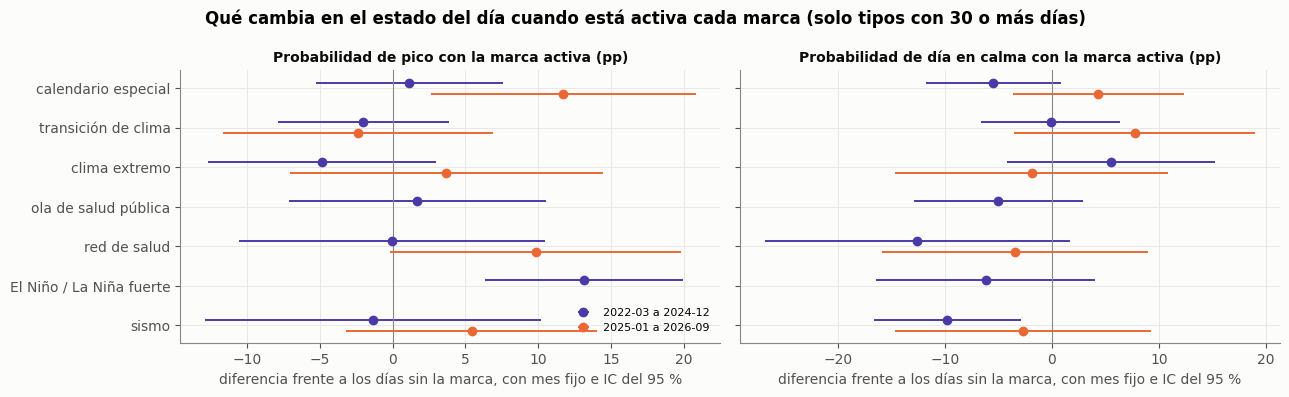

In [9]:
sys.path.insert(0, str(RAIZ / "notebooks")); import marcas
MT = marcas.marcar(pd.date_range("2020-01-01", FIN))
TIPOS = [t for t in marcas.TIPOS if t != "COVID"]
M = MT.reindex(dias)
fuera = MT[~MT.COVID]
print(f"Fuera de la COVID, {fuera.estable.sum()} de {len(fuera)} días ({fuera.estable.mean():.1%}) no tienen ninguna marca: son los días estables del entorno.")
print(f"Con la COVID dentro, {MT.estable.sum()} de {len(MT)} ({MT.estable.mean():.1%}).")
print(f"En la ventana de este cuaderno (2022-03 a 2026-09): {M.estable.sum()} de {len(M)} días ({M.estable.mean():.1%}).")

q_vol = vol.quantile([1 / 3, 2 / 3]); estab = vol <= q_vol.iloc[0]
calma = (estado == "normal") & estab                   # día normal dentro de un tramo estable
MES = pd.get_dummies(pd.Index(dias.month), prefix="m", drop_first=True).set_index(dias).astype(float)

def lpm(y, g, per):
    # modelo lineal de probabilidad: 1[estado] ~ marca + mes fijo, errores HAC de 7 días; devuelve puntos porcentuales
    D = pd.concat([y.rename("y").astype(float), g.rename("g").astype(float), MES], axis=1).loc[slice(*per)].dropna()
    Z = D.drop(columns="y"); Z = Z.loc[:, Z.std() > 0].copy(); Z.insert(0, "c", 1.0)
    r = sm.OLS(D.y, Z).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    return r.params["g"] * 100, r.bse["g"] * 100, r.pvalues["g"], int(D.g.sum())

SALIDAS = {"pico": (estado == "pico"), "bajo": (estado == "bajo"), "calma": calma}
filas = []
for t in TIPOS:
    for nom, y in SALIDAS.items():
        for per, rg in [("desc", DESC), ("conf", CONF)]:
            b, se, p, n = lpm(y.where(estado.notna()), M[t], rg)
            filas.append({"tipo": t, "estado": nom, "periodo": per, "pp": b, "se": se, "p": p, "días con marca": n})
TM = pd.DataFrame(filas)
tab = TM.pivot_table(index="tipo", columns=["estado", "periodo"], values="pp").reindex(TIPOS).round(1)
pv = TM.pivot_table(index="tipo", columns=["estado", "periodo"], values="p").reindex(TIPOS).round(3)
dias_marca = TM[TM.estado == "pico"].pivot_table(index="tipo", columns="periodo", values="días con marca").reindex(TIPOS)
tab[("días con marca", "desc")] = dias_marca["desc"]; tab[("días con marca", "conf")] = dias_marca["conf"]
print("Diferencia en puntos porcentuales de la probabilidad del estado, día con marca frente a día sin ella (mes fijo):")
display(tab)
print("Valores p (errores HAC de 7 días):")
display(pv)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, nom, tit in [(axes[0], "pico", "Probabilidad de pico"), (axes[1], "calma", "Probabilidad de día en calma")]:
    for off, per, col in [(-.14, "desc", VIOLETA), (.14, "conf", NARANJA)]:
        s = TM[(TM.estado == nom) & (TM.periodo == per)].set_index("tipo").reindex(TIPOS)
        ok = (s["días con marca"] >= 30).values
        y = np.arange(len(TIPOS)) + off
        ax.errorbar(s.pp[ok], y[ok], xerr=1.96 * s.se[ok], fmt="o", color=col, ms=6, lw=1.4,
                    label="2022-03 a 2024-12" if per == "desc" else "2025-01 a 2026-09")
    ax.axvline(0, color=MUDO, lw=.8); ax.set_title(tit + " con la marca activa (pp)", fontsize=10)
    ax.set_xlabel("diferencia frente a los días sin la marca, con mes fijo e IC del 95 %")
axes[0].set_yticks(range(len(TIPOS)), TIPOS); axes[0].invert_yaxis(); axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Qué cambia en el estado del día cuando está activa cada marca (solo tipos con 30 o más días)", fontweight="bold")
plt.tight_layout(); plt.show()

**Lectura.** Fuera de la COVID, solo **525 de 1.739 días (30,2 %)** no tienen ninguna marca: casi siempre
hay algo activo en el entorno. Con la COVID dentro la proporción baja a 21,4 %, y en la ventana de
este cuaderno es de 31,0 %. Sobre la probabilidad de pico, ninguna marca cambia de forma estable el
resultado. La transición de clima da −2,0 pp en 2022-2024 y −2,4 pp en 2025-2026 (p > 0,5 en
ambas), y el clima extremo, −4,8 y +3,7 (p > 0,2). Hay tres excepciones, todas con reparos:

- **El Niño o La Niña fuerte:** +13,1 pp (p < 0,001, 179 días) y +35,0 pp (p = 0,001, 20 días). Tiene
  el mismo signo en los dos periodos, pero es un solo episodio en la ventana del hospital
  (cuaderno 20) y coincide con el año récord y con la entrada de SURA.
- **Calendario especial:** +11,7 pp en 2025-2026 (p = 0,011, 114 días) y solo +1,2 pp en 2022-2024.
- **Red de salud:** +9,8 pp en 2025-2026 (p = 0,054, 246 días); en 2022-2024 la marca solo estuvo
  activa 36 días y no muestra efecto.

La **ola de salud pública** tuvo 7 días marcados en 2025-2026, de modo que sus cifras en ese periodo
(−8,2 pp en pico y +42,9 pp en calma) no son interpretables y no se dibujan. En los días en calma,
el único cambio significativo es el sismo en 2022-2024 (−9,8 pp, p = 0,005), que no se repite en
2025-2026 (−2,7 pp). La cautela mayor es que cada marca activa agrupa pocos episodios, y con errores
HAC de 7 días un episodio de varias semanas cuenta como pocos datos independientes.

,días,% pico,% bajo,% calma
0,516,11.2,13.6,18.8
1,696,14.8,15.1,17.5
2,341,19.1,15.5,11.7
3 o más,112,19.6,19.6,7.1


EE            p         \
estado                                              calma  pico  calma   pico   
marcas                            periodo                                       
marcas conocidas el día anterior  2022-03 a 2024-12  1.63  1.56  0.023  0.386   
                                  2025-01 a 2026-09  2.41  2.32  0.864  0.007   
marcas del mismo día              2022-03 a 2024-12  1.66  1.51  0.018  0.411   
                                  2025-01 a 2026-09  2.49  2.35  0.796  0.004   
mismo día, sin El Niño ni La Niña 2022-03 a 2024-12  1.86  1.57  0.074  0.495   
                                  2025-01 a 2026-09  2.53  2.44  0.458  0.014   

                                                    pp por marca        
estado                                                     calma  pico  
marcas                            periodo                               
marcas conocidas el día anterior  2022-03 a 2024-12        -3.71  1.35  
                                  2025-01 a 2026-09         0.41  6.25  
marcas del mismo día              2022-03 a 2024-12        -3.93  1.25  
                                  2025-01 a 2026-09         0.64  6.72  
mismo día, sin El Niño ni La Niña 2022-03 a 2024-12        -3.33 -1.07  
                                  2025-01 a 2026-09         1.88  6.00

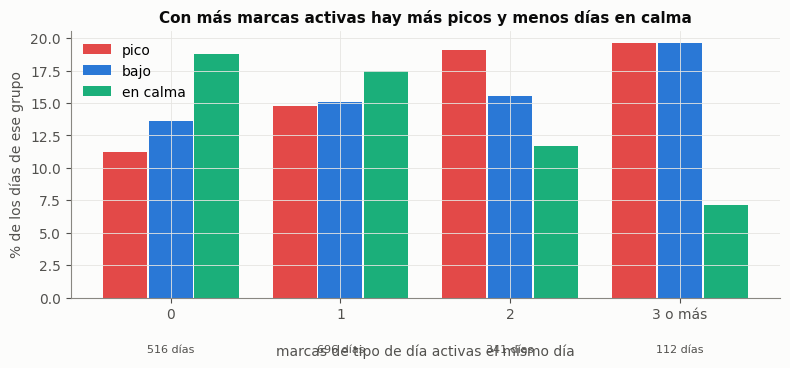

In [10]:
# dosis: cuántas marcas activas tiene el día (sin COVID: no existe en la ventana)
nm = M[TIPOS].sum(axis=1)
nm_ant = pd.concat([M[[t for t in TIPOS if t != "calendario especial"]].shift(1), M[["calendario especial"]]], axis=1).sum(axis=1)  # lo que se sabe el día anterior
nm_sn = M[[t for t in TIPOS if not t.startswith("El Ni")]].sum(axis=1)
grupo = nm.clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3 o más"})
dosis = pd.DataFrame({"días": grupo.value_counts(),
                      "% pico": (estado == "pico").groupby(grupo).mean() * 100,
                      "% bajo": (estado == "bajo").groupby(grupo).mean() * 100,
                      "% calma": calma.groupby(grupo).mean() * 100}).loc[["0", "1", "2", "3 o más"]].round(1)
display(dosis)

def pendiente(y, n, per):
    D = pd.concat([y.where(estado.notna()).rename("y").astype(float), n.rename("n"), MES], axis=1).loc[slice(*per)].dropna()
    Z = D.drop(columns="y"); Z.insert(0, "c", 1.0)
    r = sm.OLS(D.y, Z).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    return r.params["n"] * 100, r.bse["n"] * 100, r.pvalues["n"]
fil = []
for nombre, n in [("marcas del mismo día", nm), ("marcas conocidas el día anterior", nm_ant), ("mismo día, sin El Niño ni La Niña", nm_sn)]:
    for per, rg in [("2022-03 a 2024-12", DESC), ("2025-01 a 2026-09", CONF)]:
        for e, y in [("pico", estado == "pico"), ("calma", calma)]:
            b, se, p = pendiente(y, n, rg); fil.append({"marcas": nombre, "periodo": per, "estado": e, "pp por marca": round(b, 2), "EE": round(se, 2), "p": round(p, 4)})
display(pd.DataFrame(fil).pivot_table(index=["marcas", "periodo"], columns="estado", values=["pp por marca", "EE", "p"]).round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(4)
ax.bar(x - .27, dosis["% pico"], width=.26, color=ROJO, label="pico")
ax.bar(x, dosis["% bajo"], width=.26, color=AZUL, label="bajo")
ax.bar(x + .27, dosis["% calma"], width=.26, color=AQUA, label="en calma")
for i, n in enumerate(dosis["días"]): ax.text(i, -4.2, f"{n} días", ha="center", fontsize=8, color=TINTA2)
ax.set_xticks(x, dosis.index); ax.set_xlabel("marcas de tipo de día activas el mismo día", labelpad=16); ax.set_ylabel("% de los días de ese grupo")
ax.set_title("Con más marcas activas hay más picos y menos días en calma"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Lectura.** A medida que se acumulan marcas, el pico sube de **11,2 % con ninguna marca a 19,1 % con dos y 19,6 %
con tres o más**, y los días en calma bajan de 18,8 % a 7,1 %. El gradiente no es estable entre
periodos. En 2022-2024 la pendiente del pico es de +1,25 pp por marca (p = 0,41) y la de la calma
es de −3,93 pp (p = 0,018); en 2025-2026 el pico sube +6,72 pp por marca (p = 0,004) y la calma no
cambia (+0,64 pp, p = 0,80). Con las marcas que se conocen el día anterior, que son las que sirven
para predecir, el resultado es parecido: +6,25 pp en 2025-2026 (p = 0,007). Sin El Niño y La Niña, la
pendiente de 2022-2024 pasa a −1,07 pp (p = 0,50), mientras que la de 2025-2026 se mantiene en +6,00
pp (p = 0,014). **La lectura más prudente es que acumular desencadenantes perturba el día, pero en
cada periodo la perturbación toma una forma distinta:** en 2022-2024 quita días en calma sin llegar
al pico, y en 2025-2026 empuja al pico. Los dos periodos difieren también en la red de salud, así
que esta prueba no separa la dosis de la fecha. Se añadió después de la primera corrida y es
exploratoria.

In [11]:
# compuerta aplicada al barrido: cada familia solo en los días en que su gatillo está activo
def prueba_en(x, periodo, mascara):
    xs = (x - X[x.name].mean()) / X[x.name].std()
    D = pd.concat([xs.rename("x"), EST, MES], axis=1).loc[slice(*periodo)]
    D = D[mascara.reindex(D.index).fillna(False).astype(bool)].dropna()
    if len(D) < 40 or D.x.std() == 0: return None
    Z = D.drop(columns="x"); Z = Z.loc[:, Z.std() > 0].copy(); Z.insert(0, "const", 1.0)
    mc = [k for k in Z if k.startswith("m_")]
    if len(Z) <= Z.shape[1] + 10: Z = Z.drop(columns=mc)
    r = sm.OLS(D.x, Z).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    return {"pico": r.params["pico"], "p_pico": r.pvalues["pico"], "bajo": r.params["bajo"], "p_bajo": r.pvalues["bajo"], "n": len(D)}

COMP = {"clima": M["transición de clima"] | M["clima extremo"], "vigilancia": M["ola de salud pública"],
        "enso": M["El Niño / La Niña fuerte"]}
filas = []
for f, mk in COMP.items():
    cs = [c for c in X.columns if FAM[c] == f]
    for per, rg in [("desc", DESC), ("conf", CONF)]:
        for c in cs:
            o = prueba_en(X[c].rename(c), rg, mk)
            if o:
                for k in ("pico", "bajo"): filas.append({"familia": f, "var": c, "estado": k, "periodo": per, "efecto": o[k], "p": o[f"p_{k}"], "n": o["n"]})
G = pd.DataFrame(filas)
res_g = []
for f in COMP:
    n_d = int(COMP[f].loc[DESC[0]:DESC[1]].sum()); n_c = int(COMP[f].loc[CONF[0]:CONF[1]].sum())
    d = G[(G.familia == f) & (G.periodo == "desc")].reset_index(drop=True); c_ = G[(G.familia == f) & (G.periodo == "conf")]
    fila = {"familia": f, "días con gatillo 2022-24": n_d, "días con gatillo 2025-26": n_c, "pruebas": len(d)}
    if len(d):
        d["q"] = multipletests(d.p, method="fdr_bh")[1]
        sob = d[d.q < .10].merge(c_, on=["var", "estado"], suffixes=("", "_c"), how="left")
        fila.update({"p < 0,05": int((d.p < .05).sum()), "azar esperaría": round(.05 * len(d), 1), "sobreviven BH": int((d.q < .10).sum()),
                     "se confirman": int(((np.sign(sob.efecto) == np.sign(sob.efecto_c)) & (sob.p_c < .05)).sum())})
    res_g.append(fila)
display(pd.DataFrame(res_g).set_index("familia"))

,días con gatillo 2022-24,días con gatillo 2025-26,pruebas,"p < 0,05",azar esperaría,sobreviven BH,se confirman
familia,,,,,,,
clima,333,145,132,34,6.6,21,0
vigilancia,210,7,66,6,3.3,0,0
enso,182,20,4,0,0.2,0,0


**Lectura.** Aplicar la compuerta a las exposiciones no rescata al clima del mismo día. Con el gatillo
de clima (333 días en 2022-2024 y 145 en 2025-2026), 34 de 132 pruebas dan p < 0,05 (el azar daría
6,6) y 21 sobreviven a Benjamini-Hochberg, pero ninguna se confirma; sin compuerta eran 33
sobrevivientes y 3 confirmadas. La compuerta de salud pública, que sí funcionó al predecir con
origen rodante, no se puede evaluar en este diseño: tuvo 210 días activos en 2022-2024 y **solo 7 en
2025-2026**, y las 66 pruebas de vigilancia no dan nada (6 con p < 0,05, el azar daría 3,3, y
ninguna sobrevive). El ENSO tiene 182 y 20 días, y tampoco da nada. Este cuaderno no puede decir que
la ola de salud pública no actúa: no hubo olas en el periodo de confirmación. Tampoco puede
separar el ENSO de la fecha, porque cada fase es un solo episodio.

---
# 7. Los días en calma: cómo se comporta el entorno cuando el triage está estable

Un día **en calma** es un día normal (|z| ≤ 0,5) dentro de un tramo estable (tercil bajo de la
desviación típica móvil de 14 días). Es el contraste natural del pico: si el entorno explica los
sobresaltos, debería comportarse distinto cuando no hay ninguno. Se mira de dos formas: cuántos
días en calma hay según las marcas activas (figura anterior) y cómo se desplazan las exposiciones
en los días en calma, pico y bajo frente al resto, con el mes fijo, tanto en su **nivel** como en
su **movimiento** (el tamaño del cambio, sin signo).

267 días en calma de 1662 (16.0%); tramo estable (tercil bajo): 33.2% de los días
Días en calma según las marcas: sin marca activa 18.8%, con 3 o más 7.1%
Días estables para el entorno (516): 18.8% en calma y 11.2% pico; los demás: 14.8% en calma y 16.5% pico


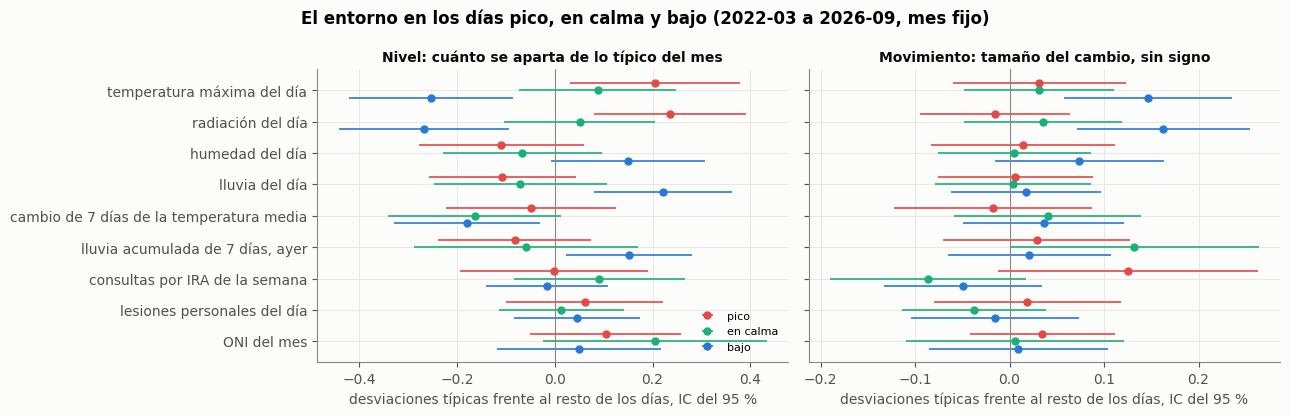

,variable,medida,estado,efecto,ee,p
0,radiación del día,movimiento,bajo,0.163,0.047,0.000
1,temperatura máxima del día,movimiento,bajo,0.146,0.045,0.001
2,"lluvia acumulada de 7 días, ayer",movimiento,calma,0.132,0.067,0.050
3,lluvia del día,nivel,bajo,0.221,0.072,0.002
4,temperatura máxima del día,nivel,bajo,-0.253,0.086,0.003
5,radiación del día,nivel,bajo,-0.268,0.089,0.003
6,cambio de 7 días de la temperatura media,nivel,bajo,-0.180,0.076,0.018
7,"lluvia acumulada de 7 días, ayer",nivel,bajo,0.152,0.066,0.022
8,radiación del día,nivel,pico,0.236,0.080,0.003
9,temperatura máxima del día,nivel,pico,0.205,0.089,0.021


In [12]:
print(f"{int(calma.sum())} días en calma de {int(estado.notna().sum())} ({calma.mean():.1%}); tramo estable (tercil bajo): {estab.mean():.1%} de los días")
print(f"Días en calma según las marcas: sin marca activa {calma[nm == 0].mean():.1%}, con 3 o más {calma[nm >= 3].mean():.1%}")
print(f"Días estables para el entorno ({int(M.estable.sum())}): {calma[M.estable].mean():.1%} en calma y {(estado == 'pico')[M.estable].mean():.1%} pico; "
      f"los demás: {calma[~M.estable].mean():.1%} en calma y {(estado == 'pico')[~M.estable].mean():.1%} pico")

VARS_C = {"temp_max|t": "temperatura máxima del día", "radiacion|t": "radiación del día", "humedad|t": "humedad del día",
          "lluvia_dia|t": "lluvia del día", "temp_media_cambio7|t-1": "cambio de 7 días de la temperatura media",
          "lluvia_7d|t-1": "lluvia acumulada de 7 días, ayer", "ira_total|misma_sem": "consultas por IRA de la semana",
          "lesiones_personales|t": "lesiones personales del día", "oni|mes": "ONI del mes"}
est4 = pd.DataFrame({"pico": (estado == "pico"), "bajo": (estado == "bajo"), "calma": calma}, index=dias).astype(float)
est4[estado.isna()] = np.nan
filas = []
for v, nom in VARS_C.items():
    xs = (X[v] - X[v].mean()) / X[v].std()
    for medida, y in [("nivel", xs), ("movimiento", xs.abs())]:
        D = pd.concat([y.rename("x"), est4, MES], axis=1).dropna()
        Z = D.drop(columns="x"); Z.insert(0, "c", 1.0)
        r = sm.OLS(D.x, Z).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
        for e in ("pico", "bajo", "calma"):
            filas.append({"variable": nom, "medida": medida, "estado": e, "efecto": r.params[e], "ee": r.bse[e], "p": r.pvalues[e]})
CE = pd.DataFrame(filas)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, medida, tit in [(axes[0], "nivel", "Nivel: cuánto se aparta de lo típico del mes"), (axes[1], "movimiento", "Movimiento: tamaño del cambio, sin signo")]:
    for off, e, col in [(-.24, "pico", ROJO), (0, "calma", AQUA), (.24, "bajo", AZUL)]:
        s = CE[(CE.medida == medida) & (CE.estado == e)].set_index("variable").reindex(list(VARS_C.values()))
        ax.errorbar(s.efecto, np.arange(len(s)) + off, xerr=1.96 * s.ee, fmt="o", color=col, ms=5, lw=1.2, label={"pico": "pico", "calma": "en calma", "bajo": "bajo"}[e])
    ax.axvline(0, color=MUDO, lw=.8); ax.set_title(tit, fontsize=10); ax.set_xlabel("desviaciones típicas frente al resto de los días, IC del 95 %")
axes[0].set_yticks(range(len(VARS_C)), list(VARS_C.values())); axes[0].invert_yaxis(); axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("El entorno en los días pico, en calma y bajo (2022-03 a 2026-09, mes fijo)", fontweight="bold")
plt.tight_layout(); plt.show()
CE.query("p < .05").round(3).sort_values(["medida", "estado", "p"]).reset_index(drop=True)

**Lectura.** Hay 267 días en calma (16,0 % de la ventana), y el tramo estable cubre el 33,2 % de los días.
La calma depende de los desencadenantes: ocurre en 18,8 % de los días sin ninguna marca y en 7,1 %
de los que tienen tres o más. Entre los días estables para el entorno, el 18,8 % está en calma y el
11,2 % en pico, contra 14,8 % y 16,5 % en los demás. **El entorno, en cambio, no se comporta de
forma distinta en los días en calma:** de las 18 comparaciones de la figura (9 variables, nivel y
movimiento), solo una es significativa para la calma (el movimiento de la lluvia acumulada de 7
días, +0,13 desviaciones, p = 0,050), que es lo que el azar esperaría. En los días pico la radiación (+0,24,
p = 0,003) y la temperatura máxima (+0,21, p = 0,021) están por encima de lo típico, que es la firma
del día soleado de la sección 8 promediada en toda la ventana. En los días bajo el entorno es
más fresco, más nublado y más cambiante: radiación −0,27, temperatura máxima −0,25, lluvia del día
+0,22, y movimiento mayor en radiación (+0,16) y temperatura máxima (+0,15). Los días bajo
tienen entonces una firma de entorno más clara que los de calma. Calma significa ausencia de
gatillos, no un entorno quieto. La cautela es que el promedio de 2022-2026 mezcla los dos
periodos en que la firma del pico tiene signos opuestos, y que son pruebas del mismo día, que
describen sin anticipar.

---
# 8. El clima: la firma del día soleado y su desaparición en 2025

La lista de la sección 5 tiene un patrón. En 2022-2024 los días pico eran **cálidos, soleados,
secos y ventosos**, el mismo día y la semana anterior: el «+1 a +2 % en la semana soleada» del
cuaderno 12 visto por días. En 2025-2026 esas mismas ventanas cambian de signo. Se muestra el perfil
completo por ventana y después año por año.

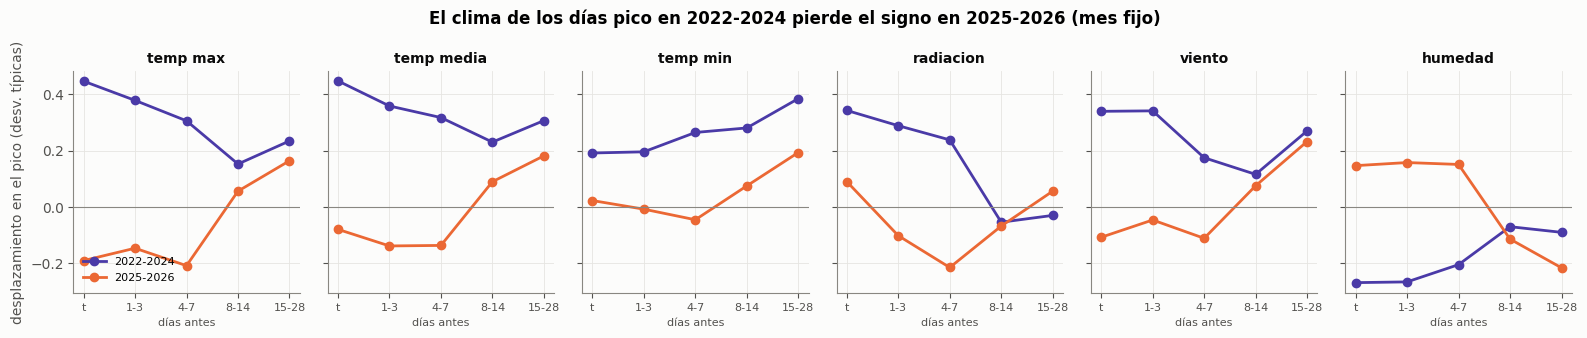

,2022,2023,2024,2025,2026
"desplazamiento en el pico, por año",,,,,
temp_max|t,0.26,0.26,0.32,-0.18,-0.09
radiacion|t,0.27,0.27,0.42,0.06,0.28
temp_min|t-15a28,-0.16,0.03,0.07,0.05,0.06
viento|t-15a28,0.02,-0.09,0.02,0.03,0.28


In [13]:
VARS = ["temp_max", "temp_media", "temp_min", "radiacion", "viento", "humedad"]
VV = list(VENT)
fig, axes = plt.subplots(1, len(VARS), figsize=(16, 3.4), sharey=True)
for ax, vname in zip(axes, VARS):
    s = W[(W["var"].str.startswith(vname + "|")) & W.estado.eq("pico")].set_index("var")
    s = s.reindex([f"{vname}|{k}" for k in VV])
    ax.plot(range(5), s.efecto_desc_mes.values, "-o", color=VIOLETA, lw=2, ms=6, label="2022-2024")
    ax.plot(range(5), s.efecto_conf_mes.values, "-o", color=NARANJA, lw=2, ms=6, label="2025-2026")
    ax.axhline(0, color=MUDO, lw=.8); ax.set_xticks(range(5), ["t", "1-3", "4-7", "8-14", "15-28"], fontsize=8)
    ax.set_title(vname.replace("_", " "), fontsize=10); ax.set_xlabel("días antes", fontsize=8)
axes[0].set_ylabel("desplazamiento en el pico (desv. típicas)"); axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("El clima de los días pico en 2022-2024 pierde el signo en 2025-2026 (mes fijo)", fontweight="bold"); plt.tight_layout(); plt.show()

por_anio = {}
for vname in ["temp_max|t", "radiacion|t", "temp_min|t-15a28", "viento|t-15a28"]:
    por_anio[vname] = {y: round(prueba(X[vname].rename(vname), (f"{y}-01-01", f"{y}-12-31"))["pico"], 2) for y in range(2022, 2027)}
pd.DataFrame(por_anio).T.rename_axis("desplazamiento en el pico, por año")

**Lectura.** El «día pico cálido y soleado» es real en 2022, 2023 y 2024: la temperatura máxima del día da
+0,26, +0,26 y +0,32 desviaciones, con el mismo signo cada año. **En 2025 y 2026 se apaga** (−0,18 y
−0,09). La radiación del mismo día aguanta mejor (+0,27, +0,27, +0,42, +0,06 y +0,28): el sol del
día sigue acompañando a los picos, salvo en 2025. Un efecto que se repite tres años y después cambia
no parece azar, y hay tres candidatos que coinciden en la fecha y que este análisis no puede separar:
el choque de la red de Nueva EPS en 2025, el episodio de El Niño de 2023-2024 (cuaderno 20, +3,6 %
sobre el triage, un solo episodio) y la entrada de SURA en 2024 (cuaderno 18). Si la relación con
el día soleado era de acceso (la gente sale, se mueve, va a consulta), un cambio en quién entra al
hospital la altera.

Lo «confirmado» en la sección 5 (temperatura y viento de hace 15 a 28 días) no aguanta año por
año: la temperatura mínima da −0,16, +0,03, +0,07, +0,05 y +0,06, y el viento, +0,02, −0,09, +0,02,
+0,03 y +0,28. La confirmación sale de diferencias entre años y de un solo año (el viento de 2026),
no de la dinámica de días, de modo que **no se toma como hallazgo**: el criterio de confirmación
lo deja pasar y la comprobación año por año lo desmonta.

## 8.1 La firma por aseguradora

Si el cambio de 2025 fuera de acceso a la red de Nueva EPS, la firma del día soleado debería
conservarse en los pacientes de las demás aseguradoras. Se construye el estado de cada grupo con el
mismo control (día de la semana, calendario, año y escalones de la red) sobre su propio conteo
diario, y se repite la prueba de la temperatura máxima y la radiación del mismo día, año por año.

In [14]:
te = pd.read_parquet(RAIZ / "salidas/triage_entidad.parquet", columns=["dia", "entidad_oid", "n"]); te["dia"] = pd.to_datetime(te.dia)
gr = pd.read_csv(RAIZ / "salidas/entidades_clasificadas.csv")[["entidad_oid", "grupo"]].drop_duplicates("entidad_oid")
te = te.merge(gr, on="entidad_oid", how="left")
te["g"] = np.where(te.grupo.eq("nueva_eps"), "Nueva EPS", "resto de aseguradores")
Dg = te.pivot_table(index="dia", columns="g", values="n", aggfunc="sum").reindex(dias).fillna(0); Dg[tri.isna()] = np.nan
display(Dg.groupby(Dg.index.year).mean().round(1).rename_axis("triages por día"))
Zc = pd.concat([dsem, calc, anio, red], axis=1)
est_g = {k: estados(ajusta(Zc, Dg[k].clip(lower=.5))) for k in Dg.columns}

def prueba_g(xname, e, per):
    x = X[xname]; xs = (x - x.mean()) / x.std()
    E = pd.DataFrame({"pico": (e == "pico").astype(float), "bajo": (e == "bajo").astype(float)}, index=dias); E[e.isna()] = np.nan
    D = pd.concat([xs.rename("x"), E, MES], axis=1).loc[slice(*per)].dropna()
    Z = D.drop(columns="x"); Z = Z.loc[:, Z.std() > 0].copy(); Z.insert(0, "c", 1.0)
    mc = [k for k in Z if k.startswith("m_")]
    if mc and (Z[mc].sum(axis=1) == 1).all(): Z = Z.drop(columns=mc[0])
    r = sm.OLS(D.x, Z).fit(cov_type="HAC", cov_kwds={"maxlags": 7}); return r.params["pico"], r.pvalues["pico"]
fil = []
for xn in ["temp_max|t", "radiacion|t"]:
    for k in Dg.columns:
        fila = {"exposición": xn, "grupo": k}
        for y in range(2022, 2027): fila[str(y)] = round(prueba_g(xn, est_g[k], (f"{y}-01-01", f"{y}-12-31"))[0], 2)
        d_, c_ = prueba_g(xn, est_g[k], DESC), prueba_g(xn, est_g[k], CONF)
        fila.update({"2022-24": round(d_[0], 2), "p 2022-24": round(d_[1], 3), "2025-26": round(c_[0], 2), "p 2025-26": round(c_[1], 3)})
        fil.append(fila)
pd.DataFrame(fil).set_index(["exposición", "grupo"])

g,Nueva EPS,resto de aseguradores
triages por día,,
2022,127.9,63.0
2023,122.9,69.5
2024,125.6,101.3
2025,115.8,83.8
2026,72.2,100.4


2022  2023  2024  2025  2026  2022-24  \
exposición  grupo                                                          
temp_max|t  Nueva EPS              0.10  0.22  0.53 -0.22 -0.01     0.29   
            resto de aseguradores  0.24  0.12  0.41 -0.14 -0.03     0.40   
radiacion|t Nueva EPS              0.26  0.06  0.50 -0.01  0.13     0.23   
            resto de aseguradores  0.39  0.08  0.34  0.06  0.05     0.29   

                                   p 2022-24  2025-26  p 2025-26  
exposición  grupo                                                 
temp_max|t  Nueva EPS                  0.006    -0.12      0.316  
            resto de aseguradores      0.000    -0.10      0.363  
radiacion|t Nueva EPS                  0.015     0.04      0.766  
            resto de aseguradores      0.000     0.09      0.490

**Lectura.** La firma del día soleado de 2022-2024 está en los dos grupos: la temperatura máxima da +0,29
(p = 0,006) en Nueva EPS y +0,40 (p < 0,001) en el resto de aseguradores, y la radiación +0,23 y
+0,29. **En 2025-2026 desaparece también en los dos:** −0,12 y −0,10 en la temperatura máxima (p =
0,32 y 0,36), +0,04 y +0,09 en la radiación. Año por año el resto pasa de +0,41 en 2024 a −0,14 en
2025, y Nueva EPS de +0,53 a −0,22. Si el cambio fuera solo de acceso a Nueva EPS, el resto de
aseguradores debería conservar la firma, y no la conserva. El resultado no descarta la hipótesis de
la red, porque el resto también cambió de composición (SURA pasó de 8,6 triages por día en 2020 a 69,6 en
2024, cuaderno 18, y el resto de aseguradores subió de 63 a 101 por día entre 2022 y 2024), y con
conteos diarios menores los estados de cada grupo son más ruidosos. Lo que sí muestra es que la
pérdida de la firma no es un fenómeno propio de un asegurador, y la fecha sigue sin poder separarse
del conjunto de cambios de 2025.

---
# 9. La hipótesis de transición, de un mes cálido a una semana fresca

El mecanismo que motivó el proyecto es un cambio de régimen: después de un periodo cálido y seco,
una semana fresca y húmeda. Entre el cambio y la consulta median días de incubación y de decisión,
así que se mira a rezagos de varios días. La variable se define con las ventanas ya construidas:
la temperatura media del mes pasado (15 a 28 días antes) menos la de la semana reciente (1 a 7 días
antes), ambas como anomalías del mes. **Esta variable se definió después de ver los resultados de
la sección 8: es una hipótesis, no un hallazgo.**

,pico,p_pico,bajo,p_bajo
2022-2024,-0.098,0.318,0.059,0.535
2025-2026,0.277,0.022,-0.097,0.460


,días,días con enfriamiento alto,episodios,% pico con enfriamiento alto,% pico resto,"desvío medio con enfriamiento alto, %","desvío medio resto, %"
periodo,,,,,,,
2022-2024,1034,98,15,7.1,15.3,-2.6,0.3
2025-2026,628,67,9,20.9,14.8,1.1,-0.1


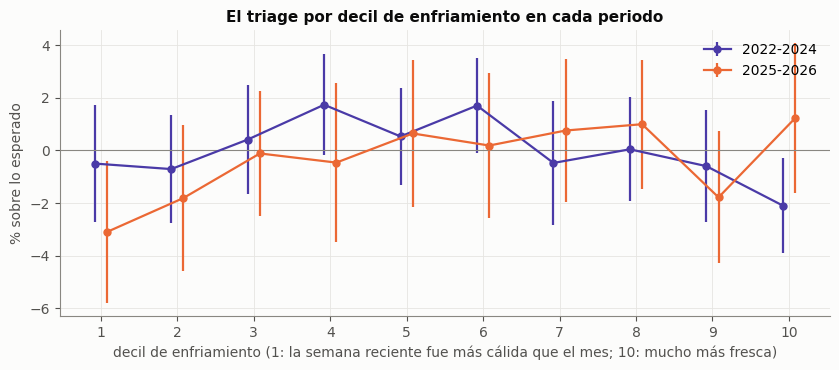

In [15]:
X["enfriamiento"] = X["temp_media|t-15a28"] - (3 * X["temp_media|t-1a3"] + 4 * X["temp_media|t-4a7"]) / 7
res = pd.DataFrame({per: prueba(X["enfriamiento"].rename("enfriamiento"), rg) for per, rg in [("2022-2024", DESC), ("2025-2026", CONF)]}).T.round(3)
display(res)

# episodios independientes: días con enfriamiento en el decil superior de toda la ventana, separados por más de 7 días
umbral = X["enfriamiento"].reindex(dias).quantile(.90)
alto = (X["enfriamiento"].reindex(dias) >= umbral)
ini_ep = alto & ~alto.shift(1, fill_value=False).rolling(7, min_periods=1).max().astype(bool)
tabla = []
for per, rg in [("2022-2024", DESC), ("2025-2026", CONF)]:
    sl = slice(*rg); ep = ini_ep.loc[sl]; a = alto.loc[sl]; e = estado.loc[sl]; r_ = R.loc[sl]
    tabla.append({"periodo": per, "días": int(e.notna().sum()), "días con enfriamiento alto": int(a.sum()), "episodios": int(ep.sum()),
                  "% pico con enfriamiento alto": round((e[a] == "pico").mean() * 100, 1), "% pico resto": round((e[~a] == "pico").mean() * 100, 1),
                  "desvío medio con enfriamiento alto, %": round(pct(r_[a].mean()), 1), "desvío medio resto, %": round(pct(r_[~a].mean()), 1)})
display(pd.DataFrame(tabla).set_index("periodo"))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for per, rg, col, off in [("2022-2024", DESC, VIOLETA, -.08), ("2025-2026", CONF, NARANJA, .08)]:
    d = pd.concat([X["enfriamiento"].reindex(dias).rename("x"), R.rename("r")], axis=1).loc[slice(*rg)].dropna()
    d["dec"] = pd.qcut(d.x, 10, labels=False)
    g = d.groupby("dec").r.agg(["mean", "sem"])
    ax.errorbar(g.index + off, pct(g["mean"]), yerr=pct(g["mean"] + 1.96 * g["sem"]) - pct(g["mean"]), fmt="-o", color=col, ms=5, lw=1.6, label=per)
ax.axhline(0, color=MUDO, lw=.8); ax.set_xticks(range(10), [str(i + 1) for i in range(10)])
ax.set_xlabel("decil de enfriamiento (1: la semana reciente fue más cálida que el mes; 10: mucho más fresca)"); ax.set_ylabel("% sobre lo esperado")
ax.set_title("El triage por decil de enfriamiento en cada periodo"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Lectura.** La variable de enfriamiento da **+0,28 desviaciones en los días pico de 2025-2026 (p = 0,022)** y
−0,10 en 2022-2024 (p = 0,32). El decil superior de la variable reúne 98 días en 15 episodios en
2022-2024 y 67 días en 9 episodios en 2025-2026. En 2025-2026 el 20,9 % de esos días son pico contra
14,8 % en el resto, pero en 2022-2024 la relación es inversa (7,1 % contra 15,3 %). En tamaño el
efecto es pequeño: el triage está +1,1 % sobre lo esperado en los días de enfriamiento alto de
2025-2026 (−0,1 % en el resto), y −2,6 % en 2022-2024 (+0,3 % en el resto). **Es una hipótesis, no un
hallazgo**, por cuatro razones: aparece en un solo periodo, la variable se definió después de verlo,
descansa en 9 episodios y cambia de signo en el periodo anterior. Encaja con el mecanismo (cambio de
régimen con rezago de una a cuatro semanas), pero este análisis no puede separarla de lo que cambió en
2025 (la red y la composición de los pacientes). Su confirmación requiere datos posteriores a
septiembre de 2026, con la definición fijada de antemano.

---
# 10. Conclusiones y límites

**Lo que los datos sostienen**

1. **El calendario es el 72 % de la historia diaria** y el día de la semana solo, el 57 %. Solo el
   44 % de los picos del conteo siguen siéndolo cuando se quita el calendario, y lo que queda se
   reparte parejo en la semana (sección 1).
2. **Un pico es la demanda entera que se corre, no un grupo que llega:** todas las bandas de edad suben
   entre +16 y +27 % y la composición del día no cambia (sección 3). Los picos duran 1,4 días y un
   pico duplica la probabilidad de otro al día posterior (29 % contra 15 %).
3. **La estación sobrevive al calendario** (mayo, 30 % de días pico) y la **agitación es festiva o
   institucional** (diciembre-enero y los trimestres en que se movía la red) (secciones 2 y 4).
4. **Casi siempre hay algo activo en el entorno:** fuera de la COVID, solo el 30,2 % de los días no
   tiene ninguna marca de tipo de día. Los días en calma son los que no tienen gatillos (18,8 % de
   los días sin marca, 7,1 % de los que tienen tres o más), no los de un entorno quieto: el entorno
   se comporta igual en los días en calma que en el resto (sección 7).
5. **La conclusión de la primera versión se mantiene para el barrido día a día y se matiza para los
   gatillos.** Ninguna fuente externa anticipa de forma estable los estados cuando se promedian
   todos los días, y la compuerta no rescata al clima del mismo día. Pero los desencadenantes
   acumulados sí se asocian con el estado del día, con una forma distinta en cada periodo: menos días
   en calma en 2022-2024 y más picos en 2025-2026 (+6,7 pp por marca, p = 0,004, también con las
   marcas del día anterior). Esa asociación es exploratoria y no se separa de la fecha.
6. **La firma climática de 2022-2024 (día cálido y soleado) desaparece en 2025 en todos los
   aseguradores.** Coinciden en la fecha el choque de la red, El Niño de 2023-2024 y la entrada de
   SURA, y este análisis no puede separarlos.
7. **La transición de un mes cálido a una semana fresca solo aparece en 2025-2026** (+0,28
   desviaciones, p = 0,022; 9 episodios). Es una hipótesis: se definió después de ver los datos y en
   2022-2024 tiene el signo contrario.

**Límites**

- La resolución es diaria y sobre el total. Los efectos que la literatura y el hospital muestran por
  subgrupo (la Feria en SOAT, la lluvia reciente en mayores, la madrugada de las noches festivas) no
  se ven en el conteo total.
- Las pruebas del mismo día describen y no anticipan; solo las marcas del día anterior sirven para
  predecir.
- En el periodo de confirmación la ola de salud pública tuvo 7 días y El Niño o La Niña fuerte, 20: lo
  que dependa de ellos no puede evaluarse con este diseño, y eso no equivale a que no actúen.
- Las 163 exposiciones y 326 pruebas del barrido comparten dependencia en el tiempo; los errores HAC
  de 7 días la corrigen solo en parte.
- Las secciones 6 a 9 se añadieron después de la primera corrida y son exploratorias; solo el
  barrido de la sección 5 sigue el protocolo fijado de antemano.